<h1> Basic example for the LayoutField metric </h1>
This script contains an example to understand how to use the metrics to compare different (sets of) layouts.

In [1]:
# import modules
import numpy as np
import matplotlib.pyplot as plt

# import metrics
from metrics_layout import LayoutProbabilityGrid

As an example, we define a 3x3 regular layout $(\boldsymbol{x}_R,\boldsymbol{y}_R)$. 

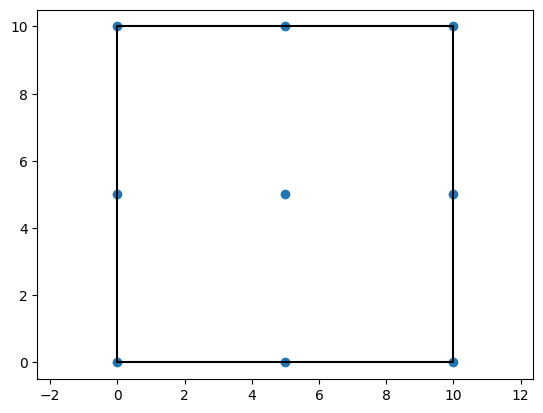

In [2]:
# define regular layout (x_R,y_R)
x_boundaries = np.array([0.,10.,10.,0.,0.])
y_boundaries = np.array([0.,0.,10.,10.,0.])
x_R = np.array([0.,5.,10.,0.,5.,10.,0.,5.,10.])
y_R = np.array([0.,0.,0.,5.,5.,5.,10.,10.,10.])

# plot regular layout
plt.figure()
plt.plot(x_boundaries,y_boundaries,c='k')
plt.scatter(x_R,y_R)
plt.axis('equal')
plt.show()



We compute the Layout field defined as:

$$
\mathrm{LF}_R(x,y)=\sum_{i=1}^{N_{\mathrm{wt}}} \frac{1}{2\pi\sigma ^2}\cdot \exp\left(-\frac{(x-x_{R,i})^2+(y-y_{R,i})^2}{2\sigma^2}\right) \quad .
$$

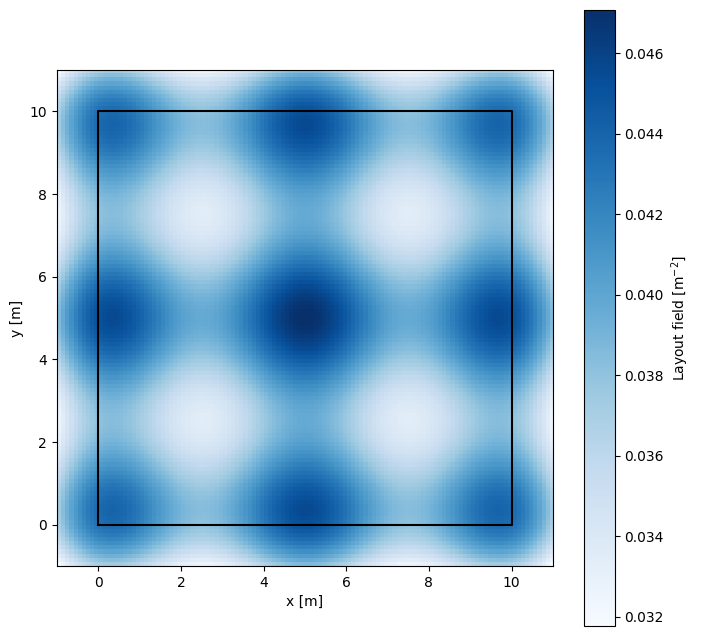

In [3]:
# define layout field object
layout_p_grid = LayoutProbabilityGrid(x_boundaries=x_boundaries, y_boundaries=y_boundaries, diameter=1.,res_D=0.1)

# define sigma (expressed as multiple of rotor diameter)
sigma_D = 2.

# plot Layout field
layout_p_grid.plot_probability_grid([x_R],[y_R],sigma_D=sigma_D)

Define 4 different layouts randomly from the initial regular layout.

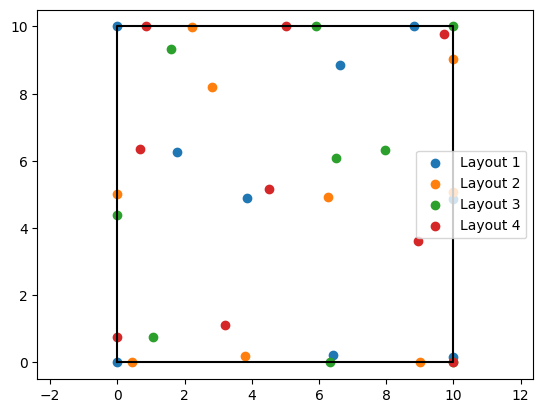

In [4]:
# define 4 random layouts using random steps to move the turbine from the initial 3x3 regular layout
x_min = np.min(x_boundaries)
x_max = np.max(x_boundaries)
y_min = np.min(y_boundaries)
y_max = np.max(y_boundaries)
step_min = 1.
step_max = 2.5
x_1 = np.minimum(np.maximum(x_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.cos(2*np.pi*np.random.rand(len(x_R))),x_min),x_max)
y_1 = np.minimum(np.maximum(y_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.random.rand(len(y_R))*np.cos(2*np.pi*np.random.rand(len(y_R))),y_min),y_max)
x_2 = np.minimum(np.maximum(x_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.cos(2*np.pi*np.random.rand(len(x_R))),x_min),x_max)
y_2 = np.minimum(np.maximum(y_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.random.rand(len(y_R))*np.cos(2*np.pi*np.random.rand(len(y_R))),y_min),y_max)
x_3 = np.minimum(np.maximum(x_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.cos(2*np.pi*np.random.rand(len(x_R))),x_min),x_max)
y_3 = np.minimum(np.maximum(y_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.random.rand(len(y_R))*np.cos(2*np.pi*np.random.rand(len(y_R))),y_min),y_max)
x_4 = np.minimum(np.maximum(x_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.cos(2*np.pi*np.random.rand(len(x_R))),x_min),x_max)
y_4 = np.minimum(np.maximum(y_R+((step_max-step_min)*np.random.rand(len(x_R))+step_min)*np.random.rand(len(y_R))*np.cos(2*np.pi*np.random.rand(len(y_R))),y_min),y_max)

# plot layouts
plt.figure()
plt.plot(x_boundaries,y_boundaries,c='k')
plt.scatter(x_1,y_1,label='Layout 1')
plt.scatter(x_2,y_2,label='Layout 2')
plt.scatter(x_3,y_3,label='Layout 3')
plt.scatter(x_4,y_4,label='Layout 4')
plt.axis('equal')
plt.legend()
plt.show()


Compute the superimopsed Layout fields of the layouts 1 and 2 ($LF_{1\&2}$), and the layouts 3 and 4 ($LF_{3\&4}$).

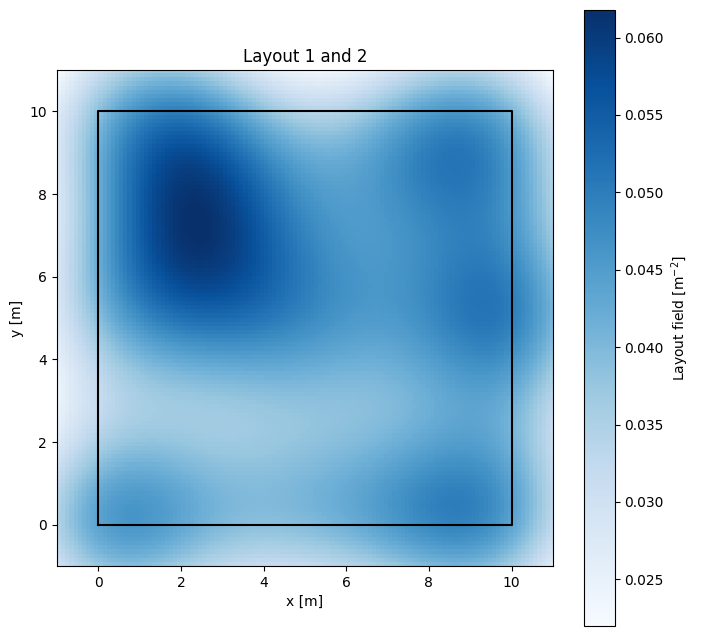

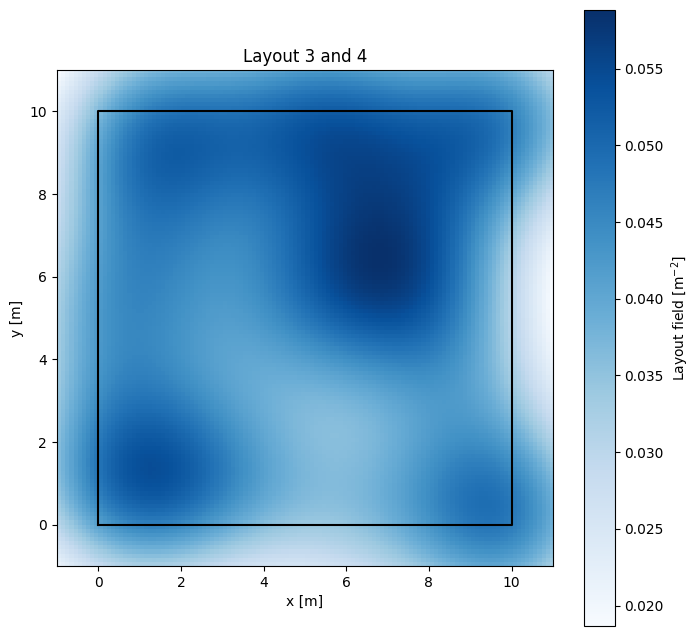

In [5]:
# plot superimposed Layout field (layout 1 and 2)
layout_p_grid.plot_probability_grid([x_1,x_2],[y_1,y_2],sigma_D=sigma_D,title='Layout 1 and 2')

# plot superimposed Layout field (layout 3 and 4)
layout_p_grid.plot_probability_grid([x_3,x_4],[y_3,y_4],sigma_D=sigma_D,title='Layout 3 and 4')


Compute the Layout field error (LFE), defined as:

$$
\mathrm{LFE}(x,y)=\mathrm{LF}_{1\&2}(x,y)-\mathrm{LF}_{3\&4}(x,y) \quad .
$$

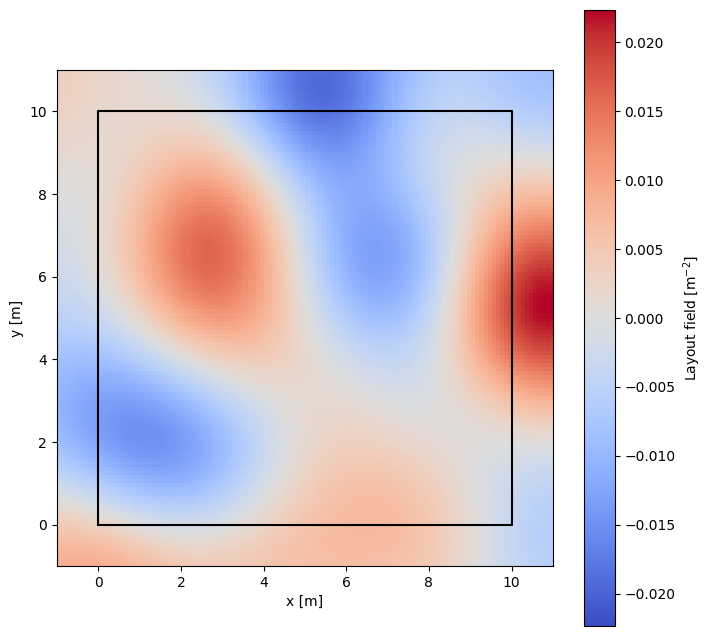

In [6]:
# plot Layout field error: LF 1&2 (in red) - LF 3&4 (in blue)
layout_p_grid.plot_diff_grid([x_1,x_2],[y_1,y_2],[x_3,x_4],[y_3,y_4],sigma_D=sigma_D)


Calculate the Layout field integrated error ($\mathrm{LFIE}$), defined as

$$
\mathrm{LFIE} = \iint_{\mathbb{R}^2}\left\vert \mathrm{LFE}(x,y) \right\vert \,\mathrm{d}x \, \mathrm{d}y\quad ,
$$

and the Effective layout distance ($d_\mathrm{eff}$), defined as

$$
d_{\mathrm{eff}} = 2\sqrt{2}\sigma\cdot \mathrm{erf}^{-1}\left(\frac{\mathrm{LFIE}}{2\cdot N_\mathrm{wt}}\right) \quad .
$$

In [8]:
# calculate LFIE
lfie = layout_p_grid.calculate_integrated_diff([x_1,x_2],[y_1,y_2],[x_3,x_4],[y_3,y_4],sigma_D=sigma_D)

# calculate d_eff
n_wt = 9    # number of turbines
d_eff = layout_p_grid.calculate_d_eff([x_1,x_2],[y_1,y_2],[x_3,x_4],[y_3,y_4],sigma_D=sigma_D,n_wt=n_wt)

# extract diameter to normalize d_eff
diameter = layout_p_grid.diameter

print(f'LFIE [-]: {lfie}')
print(f'd_eff [D]: {d_eff/diameter}')

LFIE [-]: 0.8970848902629586
d_eff [D]: 0.25001361952272555
